# Vòng 4 — Rule Engine & báo cáo tự động

**Nguyên tắc thiết kế (rút kinh nghiệm từ v1)**
- **Lỗi dữ liệu tách riêng khỏi cảnh báo nghiệp vụ.** v1 gắn cờ "nghi thất thoát" cho các ca nhân viên gõ tiền két theo đơn vị nghìn; v2 xếp các ca này vào nhóm *Lỗi dữ liệu*.
- **Chỉ cảnh báo điều dữ liệu thực sự chứng minh được.** Không có sổ ghi tiền rút nên *tiền ra* khỏi két không thể kết luận là thất thoát. Ngược lại, *tiền vào* két mà không có hóa đơn là dấu hiệu rõ ràng: có giao dịch không qua POS, thu nợ, nạp tiền lẻ hoặc đếm sai.
- **Mọi ngưỡng đều có bảng độ nhạy** để thấy số cảnh báo thay đổi thế nào.

| Mã | Luật | Điều kiện | Mức |
|---|---|---|---|
| DQ1 | Lỗi đơn vị tiền két | tiền két nhập < 10.000 đ (đã sửa ×1000 ở Vòng 1) | Lỗi dữ liệu |
| DQ2 | Nhãn ca sai | `is_morning_shift` không khớp giờ chốt ca | Lỗi dữ liệu |
| F1 | Tiền vào két không có hóa đơn (lớn) | `cash_flow_gap` > 100.000 đ | **Cao** |
| F2 | Tiền vào két không có hóa đơn (nhỏ) | 10.000 đ < `cash_flow_gap` ≤ 100.000 đ | Theo dõi |
| F3 | Két lệch khỏi thói quen rút tiền | robust z của mô hình Huber, \|z\| > 3 | Trung bình |
| C1 | Đơn khách quen lệch thói quen | lệch phương thức hoặc giá trị cao bất thường (Vòng 3) | Theo dõi |
| C2 | Ghi chú có giao dịch tiền ngoài hóa đơn | cho mượn, trả nợ, "20k tiền mặt"… (Vòng 3) | Theo dõi |

**Input:** `shifts_scored_v2.csv` (Vòng 2), `customer_txn_v2.csv` (Vòng 3)
**Output:** `data/processed_v2/rule_report_v2.csv`, `outputs/04_rule_summary.md`

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')

# Notebook nằm trong Final-Project/notebook-v2/ -> dữ liệu ở Final-Project/data/
ROOT = Path.cwd().resolve().parent
RAW = ROOT / 'data' / 'raw'
PROC = ROOT / 'data' / 'processed_v2'      # CSV trung gian (gitignored, có dữ liệu kinh doanh)
OUT = Path.cwd() / 'outputs'                # hình + báo cáo tổng hợp đã ẩn danh
PROC.mkdir(parents=True, exist_ok=True)
OUT.mkdir(exist_ok=True)

SEED = 42
TOL = 10_000   # tiền két được đếm tròn tới 10.000 đ -> sai số đếm ±10.000 đ

def vnd(x):
    return f"{x:,.0f} đ".replace(',', '.')

In [2]:
shifts = pd.read_csv(PROC / 'shifts_scored_v2.csv', parse_dates=['timestamp', 'prev_count_at'])
cust = pd.read_csv(PROC / 'customer_txn_v2.csv', parse_dates=['transaction_at'])
print(f"{len(shifts)} ca | {len(cust)} đơn có mã khách")

IN_HIGH = 100_000   # F1
Z_CUT = 3           # F3

236 ca | 101 đơn có mã khách


## 1. Áp luật

In [3]:
c_flag = cust[cust.flag_method | cust.flag_amount]
c_note = cust[cust.flag_money_note]

def describe_customer(r):
    why = []
    if r.flag_method: why.append(f"trả {r.method} (thói quen ngược lại)")
    if r.flag_amount: why.append(f"giá trị {vnd(r.total_revenue)} cao bất thường")
    return f"{r.customer} lúc {r.transaction_at:%H:%M}: " + ', '.join(why)

c1_text = c_flag.groupby('shift_id').apply(lambda g: [describe_customer(r) for r in g.itertuples()])
c2_text = c_note.groupby('shift_id').apply(lambda g: [f"{r.customer} lúc {r.transaction_at:%H:%M}: ghi chú có giao dịch tiền ngoài hóa đơn" for r in g.itertuples()])

def apply_rules(r):
    data, alerts = [], []
    if r.flag_unit_typo:
        data.append(('DQ1', f"tiền két nhập {vnd(r.actual_cash_in_drawer)}, đã sửa thành {vnd(r.drawer)}"))
    if r.flag_shift_label:
        data.append(('DQ2', f"POS ghi ca {'sáng' if r.is_morning_shift else 'chiều'} nhưng chốt lúc {r.timestamp:%H:%M}"))
    gap = r.cash_flow_gap
    if gap > IN_HIGH:
        alerts.append(('F1', 'Cao', f"két dư {vnd(gap)} so với két trước + tiền mặt bán, không có hóa đơn tương ứng"))
    elif gap > TOL:
        alerts.append(('F2', 'Theo dõi', f"két dư {vnd(gap)} không có hóa đơn (có thể là đơn nhỏ chưa nhập)"))
    if abs(r.habit_z) > Z_CUT:
        side = 'nhiều' if r.habit_z > 0 else 'ít'
        alerts.append(('F3', 'Trung bình', f"két để lại {side} hơn thói quen rút tiền (z = {r.habit_z:+.1f}, dự kiến ~{vnd(r.drawer_pred)})"))
    for t in c1_text.get(r.shift_id, []):
        alerts.append(('C1', 'Theo dõi', t))
    for t in c2_text.get(r.shift_id, []):
        alerts.append(('C2', 'Theo dõi', t))
    return data, alerts

SEV_ORDER = ['Cao', 'Trung bình', 'Theo dõi']
res = shifts.apply(apply_rules, axis=1)
shifts['data_issues'] = res.map(lambda x: x[0])
shifts['alerts'] = res.map(lambda x: x[1])
shifts['rules'] = shifts.apply(lambda r: sorted({a[0] for a in r.data_issues} | {a[0] for a in r.alerts}), axis=1)
shifts['severity'] = shifts.alerts.map(lambda a: next((s for s in SEV_ORDER if any(x[1] == s for x in a)), 'Bình thường'))
shifts['has_data_issue'] = shifts.data_issues.map(len) > 0

display(shifts.severity.value_counts().reindex(SEV_ORDER + ['Bình thường'], fill_value=0).to_frame('Số ca'))
rule_counts = shifts.explode('rules').rules.value_counts().reindex(['DQ1', 'DQ2', 'F1', 'F2', 'F3', 'C1', 'C2']).fillna(0).astype(int)
display(rule_counts.to_frame('Số ca kích hoạt'))

,Số ca
severity,
Cao,10
Trung bình,0
Theo dõi,44
Bình thường,182


,Số ca kích hoạt
rules,
DQ1,5
DQ2,2
F1,10
F2,34
F3,1
C1,11
C2,1


## 2. Độ nhạy theo ngưỡng

In [4]:
sens_f1 = pd.DataFrame({'ngưỡng F1': [vnd(t) for t in [50_000, 100_000, 200_000, 300_000, 500_000]],
                        'số ca F1': [(shifts.cash_flow_gap > t).sum() for t in [50_000, 100_000, 200_000, 300_000, 500_000]]})
sens_f3 = pd.DataFrame({'ngưỡng |z| F3': [2, 2.5, 3, 3.5, 4],
                        'số ca F3': [(shifts.habit_z.abs() > z).sum() for z in [2, 2.5, 3, 3.5, 4]]})
display(sens_f1.set_index('ngưỡng F1').T)
display(sens_f3.set_index('ngưỡng |z| F3').T)

ngưỡng F1,50.000 đ,100.000 đ,200.000 đ,300.000 đ,500.000 đ
số ca F1,17,10,4,4,1


ngưỡng |z| F3,2.0,2.5,3.0,3.5,4.0
số ca F3,11,1,1,0,0


**Nhận xét:** F1 khá nhạy với ngưỡng ở vùng thấp (50k: 17 ca, 100k: 10 ca) nhưng ổn định từ 200k trở lên (4 ca). F3 chỉ có 1 ca ở mọi ngưỡng từ 2,5 trở lên, đúng như nhận xét ở Vòng 2 rằng lượng tiền rút quá thất thường để mô hình bắt được nhiều.

## 3. So với Rule Engine của bản v1

In [5]:
v1_path = ROOT / 'data' / 'processed' / 'Rule_Engine_Report.csv'
if v1_path.exists():
    v1 = pd.read_csv(v1_path, parse_dates=['timestamp'])[['timestamp', 'primary_rule']]
    j = shifts.merge(v1, on='timestamp', how='left')
    display(pd.crosstab(j.primary_rule, j.severity, margins=True, margins_name='Tổng').reindex(columns=SEV_ORDER + ['Bình thường', 'Tổng'], fill_value=0))
    r2 = j[j.primary_rule == 'R2_That_Thoat_Thuc']
    print(f"11 ca v1 gắn 'nghi thất thoát' (R2): {r2.flag_unit_typo.sum()} ca là lỗi đơn vị tiền két (DQ1); "
          f"{(r2.cash_flow_gap < -TOL).sum()} ca là tiền ra không ghi nhận (không đủ căn cứ kết luận thất thoát)")
    display(r2[['timestamp', 'shift', 'actual_cash_in_drawer', 'drawer', 'cash_flow_gap', 'habit_z', 'severity', 'rules']]
            .style.format({'actual_cash_in_drawer': vnd, 'drawer': vnd, 'cash_flow_gap': vnd, 'habit_z': '{:+.2f}'}))
else:
    print('Không có file v1 để đối chiếu.')

severity,Cao,Trung bình,Theo dõi,Bình thường,Tổng
primary_rule,,,,,
CLEAR,9,0,34,162,205
R2_That_Thoat_Thuc,0,0,0,11,11
R3_Khach_Quen,1,0,10,9,20
Tổng,10,0,44,182,236


11 ca v1 gắn 'nghi thất thoát' (R2): 5 ca là lỗi đơn vị tiền két (DQ1); 11 ca là tiền ra không ghi nhận (không đủ căn cứ kết luận thất thoát)


,timestamp,shift,actual_cash_in_drawer,drawer,cash_flow_gap,habit_z,severity,rules
1,2025-12-20 17:54:52,Chiều,860 đ,860.000 đ,-202.000 đ,-0.41,Bình thường,['DQ1']
2,2025-12-21 11:45:24,Sáng,490 đ,490.000 đ,-788.000 đ,-1.11,Bình thường,['DQ1']
5,2025-12-22 17:38:18,Chiều,1.270 đ,1.270.000 đ,-489.000 đ,-0.29,Bình thường,['DQ1']
6,2025-12-23 11:42:08,Sáng,480 đ,480.000 đ,-1.346.000 đ,-1.78,Bình thường,['DQ1']
9,2025-12-24 18:28:09,Chiều,1.230 đ,1.230.000 đ,-15.000 đ,+0.23,Bình thường,['DQ1']
33,2026-01-05 17:28:05,Chiều,200.000 đ,200.000 đ,-1.061.000 đ,-2.16,Bình thường,[]
40,2026-01-09 17:37:47,Chiều,690.000 đ,690.000 đ,-1.352.000 đ,-1.56,Bình thường,['DQ2']
110,2026-02-14 17:07:22,Chiều,590.000 đ,590.000 đ,-797.000 đ,-1.01,Bình thường,[]
159,2026-03-20 18:01:49,Chiều,900.000 đ,900.000 đ,-1.431.000 đ,-1.42,Bình thường,[]
179,2026-04-01 18:00:10,Chiều,500.000 đ,500.000 đ,-1.605.000 đ,-2.07,Bình thường,[]


**Nhận xét:** **cả 11 ca** mà v1 kết luận "nghi thất thoát" đều không bị v2 cảnh báo:
- 5 ca là **lỗi gõ đơn vị tiền két** (DQ1), sau khi sửa thì dòng tiền bình thường.
- 6 ca còn lại là tiền ra không ghi nhận, két để lại 200k–900k (thấp nhưng z chỉ −1 đến −2,2). Không có sổ ghi tiền rút thì không đủ căn cứ để gọi là thất thoát.

Ngược lại, 9 ca v1 coi là bình thường thì v2 xếp mức **Cao**: đều là ca **tiền vào két không có hóa đơn**, loại bất thường mà v1 không thể thấy vì chỉ số `Cash_Diff` của v1 luôn dương.

## 4. Báo cáo text tự động
Thuần Python, f-string theo template, không dùng LLM.

In [6]:
def shift_report(r):
    lines = [f"CA #{r.shift_id:03d} | Ca {r['shift'].lower()} | {r.timestamp:%d/%m/%Y %H:%M} | Mức: {r.severity.upper()}",
             f"Doanh thu {vnd(r.total_revenue)} ({r.bill_count} bill, tiền mặt {vnd(r.cash_amount)}) | "
             f"két {vnd(r.drawer)}, kỳ vọng nếu không rút {vnd(r.expected_drawer)}"]
    for code, text in r.data_issues:
        lines.append(f"  [Dữ liệu {code}] {text}")
    for code, sev, text in r.alerts:
        lines.append(f"  [{sev} {code}] {text}")
    if r.severity == 'Cao':
        lines.append("  → Hỏi nhân viên ca này về khoản tiền vào két; đối chiếu sổ thu nợ / đơn chưa nhập POS.")
    elif r.severity == 'Trung bình':
        lines.append("  → Hỏi chủ quán về khoản rút tiền của ca này.")
    return '\n'.join(lines)

for sev in SEV_ORDER:
    sub = shifts[shifts.severity == sev]
    if len(sub):
        print(shift_report(sub.sort_values('cash_flow_gap', ascending=False).iloc[0]), end='\n\n')

CA #049 | Ca sáng | 14/01/2026 12:02 | Mức: CAO
Doanh thu 800.000 đ (27 bill, tiền mặt 588.000 đ) | két 2.610.000 đ, kỳ vọng nếu không rút 1.638.000 đ
  [Cao F1] két dư 972.000 đ so với két trước + tiền mặt bán, không có hóa đơn tương ứng
  [Trung bình F3] két để lại nhiều hơn thói quen rút tiền (z = +3.3, dự kiến ~1.151.311 đ)
  → Hỏi nhân viên ca này về khoản tiền vào két; đối chiếu sổ thu nợ / đơn chưa nhập POS.

CA #171 | Ca chiều | 27/03/2026 18:15 | Mức: THEO DÕI
Doanh thu 1.561.000 đ (37 bill, tiền mặt 596.000 đ) | két 1.900.000 đ, kỳ vọng nếu không rút 1.826.000 đ
  [Theo dõi F2] két dư 74.000 đ không có hóa đơn (có thể là đơn nhỏ chưa nhập)



In [7]:
def monthly_report(g, month):
    sev = g.severity.value_counts()
    top = g.sort_values('cash_flow_gap', ascending=False).iloc[0]
    return '\n'.join([
        f"THÁNG {month} | {len(g)} ca | doanh thu {vnd(g.total_revenue.sum())} (tiền mặt {g.cash_amount.sum() / g.total_revenue.sum():.0%})",
        f"  Cao: {sev.get('Cao', 0)} | Trung bình: {sev.get('Trung bình', 0)} | Theo dõi: {sev.get('Theo dõi', 0)} | Lỗi dữ liệu: {g.has_data_issue.sum()}",
        f"  Tiền vào két không có hóa đơn: {(g.cash_flow_gap > TOL).sum()} ca, tổng {vnd(g.cash_flow_gap.clip(lower=0).where(g.cash_flow_gap > TOL, 0).sum())}",
        f"  Tiền rút không ghi nhận (ước tính): {vnd(-g.cash_flow_gap.where(g.cash_flow_gap < -TOL, 0).sum())}",
        f"  Ca dư két lớn nhất: #{top.shift_id:03d} ({top.timestamp:%d/%m}) {vnd(top.cash_flow_gap)}"])

shifts['month'] = shifts.timestamp.dt.to_period('M').astype(str)
for m, g in shifts.groupby('month'):
    print(monthly_report(g, m), end='\n\n')

THÁNG 2025-12 | 24 ca | doanh thu 17.420.000 đ (tiền mặt 50%)
  Cao: 0 | Trung bình: 0 | Theo dõi: 5 | Lỗi dữ liệu: 5
  Tiền vào két không có hóa đơn: 5 ca, tổng 192.000 đ
  Tiền rút không ghi nhận (ước tính): 9.502.000 đ
  Ca dư két lớn nhất: #015 (27/12) 59.000 đ

THÁNG 2026-01 | 60 ca | doanh thu 47.503.000 đ (tiền mặt 50%)
  Cao: 2 | Trung bình: 0 | Theo dõi: 10 | Lỗi dữ liệu: 1
  Tiền vào két không có hóa đơn: 10 ca, tổng 1.677.000 đ
  Tiền rút không ghi nhận (ước tính): 24.843.000 đ
  Ca dư két lớn nhất: #049 (14/01) 972.000 đ

THÁNG 2026-02 | 40 ca | doanh thu 30.522.000 đ (tiền mặt 60%)
  Cao: 5 | Trung bình: 0 | Theo dõi: 5 | Lỗi dữ liệu: 0
  Tiền vào két không có hóa đơn: 9 ca, tổng 1.257.000 đ
  Tiền rút không ghi nhận (ước tính): 17.985.000 đ
  Ca dư két lớn nhất: #090 (04/02) 389.000 đ



THÁNG 2026-03 | 55 ca | doanh thu 51.302.000 đ (tiền mặt 54%)
  Cao: 1 | Trung bình: 0 | Theo dõi: 10 | Lỗi dữ liệu: 1
  Tiền vào két không có hóa đơn: 7 ca, tổng 319.000 đ
  Tiền rút không ghi nhận (ước tính): 29.446.000 đ
  Ca dư két lớn nhất: #168 (25/03) 109.000 đ

THÁNG 2026-04 | 57 ca | doanh thu 44.748.000 đ (tiền mặt 49%)
  Cao: 2 | Trung bình: 0 | Theo dõi: 14 | Lỗi dữ liệu: 0
  Tiền vào két không có hóa đơn: 13 ca, tổng 961.000 đ
  Tiền rút không ghi nhận (ước tính): 22.717.000 đ
  Ca dư két lớn nhất: #219 (22/04) 377.000 đ



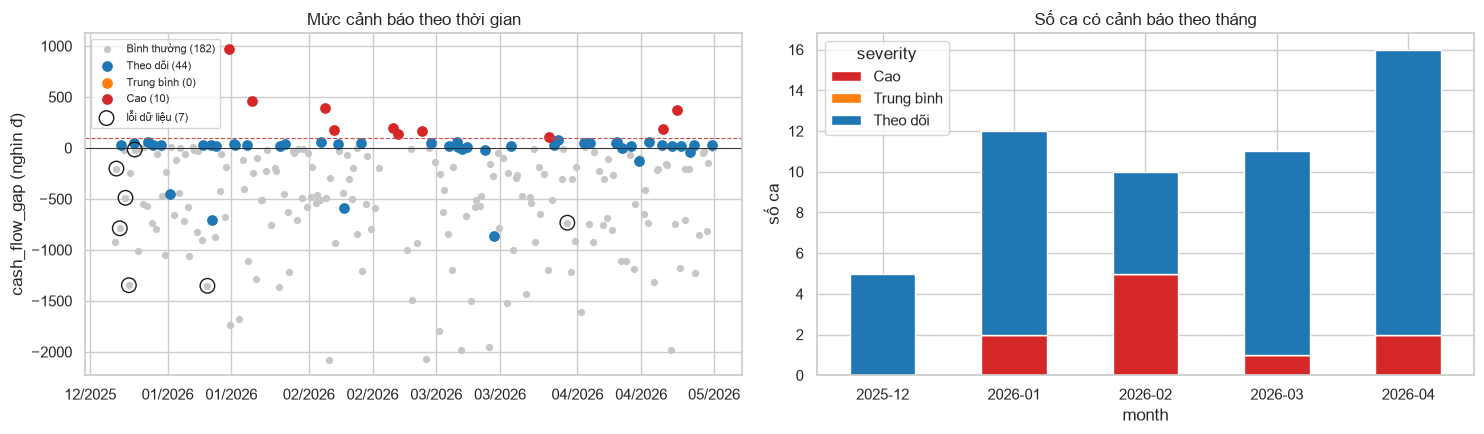

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
colors = {'Cao': '#d62728', 'Trung bình': '#ff7f0e', 'Theo dõi': '#1f77b4', 'Bình thường': '#c7c7c7'}
for s in ['Bình thường', 'Theo dõi', 'Trung bình', 'Cao']:
    g = shifts[shifts.severity == s]
    ax[0].scatter(g.timestamp, g.cash_flow_gap / 1e3, s=18 if s == 'Bình thường' else 45, c=colors[s], label=f'{s} ({len(g)})')
dq = shifts[shifts.has_data_issue]
ax[0].scatter(dq.timestamp, dq.cash_flow_gap / 1e3, s=110, facecolors='none', edgecolors='k', label=f'lỗi dữ liệu ({len(dq)})')
ax[0].axhline(0, c='k', lw=.6); ax[0].axhline(IN_HIGH / 1e3, c='r', ls='--', lw=.8)
ax[0].set_ylabel('cash_flow_gap (nghìn đ)'); ax[0].set_title('Mức cảnh báo theo thời gian'); ax[0].legend(fontsize=8)
import matplotlib.dates as mdates
ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))

pivot = shifts.groupby(['month', 'severity']).size().unstack(fill_value=0).reindex(columns=SEV_ORDER, fill_value=0)
pivot.plot.bar(stacked=True, ax=ax[1], color=[colors[c] for c in pivot.columns], rot=0)
ax[1].set_title('Số ca có cảnh báo theo tháng'); ax[1].set_ylabel('số ca')
plt.tight_layout(); plt.savefig(OUT / '04_alerts.png', dpi=120); plt.show()

**Nhận xét:** **6/10 ca mức Cao là ca sáng**, tức là phần tiền tăng xuất hiện **qua đêm**. Lời giải thích vô hại là chủ quán bỏ thêm tiền lẻ đầu ngày, vì cả bộ dữ liệu chỉ có 6 dòng mở ca cho 236 ca (3 dòng trong đó ghi 0 = không đếm). 4 ca còn lại là ca chiều (tiền tăng trong ngày) nên đáng hỏi hơn. Biện pháp đơn giản nhất để loại bỏ sự mơ hồ này là **bắt buộc đếm két khi mở ca** và ghi các khoản rút/nạp vào POS.

## 5. Lưu kết quả

In [9]:
out = shifts[['shift_id', 'timestamp', 'shift', 'total_revenue', 'bill_count', 'cash_amount', 'drawer', 'expected_drawer',
              'cash_flow_gap', 'habit_z', 'cluster', 'severity', 'has_data_issue']].copy()
out['rules'] = shifts.rules.map(', '.join)
out['report_text'] = shifts.apply(shift_report, axis=1)
out.to_csv(PROC / 'rule_report_v2.csv', index=False)

sev_tbl = shifts.severity.value_counts().reindex(SEV_ORDER + ['Bình thường']).fillna(0).astype(int)
md_lines = ['# Tóm tắt Rule Engine v2', '', f'{len(shifts)} ca, {shifts.timestamp.min():%d/%m/%Y} – {shifts.timestamp.max():%d/%m/%Y}.', '',
            '| Mức | Số ca |', '|---|---|'] + [f'| {k} | {v} |' for k, v in sev_tbl.items()] + [
            '', '| Luật | Số ca kích hoạt |', '|---|---|'] + [f'| {k} | {v} |' for k, v in rule_counts.items()]
(OUT / '04_rule_summary.md').write_text('\n'.join(md_lines) + '\n', encoding='utf-8')
print(f"Đã lưu {len(out)} ca -> {PROC / 'rule_report_v2.csv'} và {OUT / '04_rule_summary.md'}")

Đã lưu 236 ca -> D:\Data Analysis\Data-Mining\Final-Project\data\processed_v2\rule_report_v2.csv và D:\Data Analysis\Data-Mining\Final-Project\notebook-v2\outputs\04_rule_summary.md


## ✅ Tổng kết Vòng 4
| Mức | Số ca | Ý nghĩa |
|---|---|---|
| Cao | 10 | Tiền vào két > 100k không có hóa đơn (6 ca sáng, 4 ca chiều) |
| Trung bình | 0 | Ca lệch thói quen rút tiền duy nhất (z = +3,3) đã ở mức Cao |
| Theo dõi | 44 | Tiền vào nhỏ 10–100k (34 ca), đơn khách quen lệch thói quen, ghi chú tiền ngoài hóa đơn |
| Lỗi dữ liệu | 7 ca | 5 ca gõ sai đơn vị tiền két, 2 ca sai nhãn sáng/chiều |

**Khác biệt chính so với v1:** v1 cảnh báo 11 ca "nghi thất thoát", trong đó 5 ca là lỗi gõ phím và 6 ca không đủ căn cứ. v2 cảnh báo loại bất thường **có căn cứ** (tiền xuất hiện trong két mà không có hóa đơn) và tách riêng lỗi dữ liệu. Muốn phát hiện thất thoát thật sự thì cần bổ sung dữ liệu: đếm két khi mở ca và ghi lại mọi khoản rút/nạp.